<a href="https://colab.research.google.com/github/eng-mostafa-allam/GDG-AI-Tasks/blob/main/Session_4_Task_GDG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="width:100%; background-color:#F0F0F0; border:2px solid #1E1E1E; border-radius:16px; padding:16px; margin-bottom:0; font-family:'Google Sans',Roboto,Arial,sans-serif;">
  <tr>
    <td style="width:140px; text-align:center; vertical-align:middle; border:none; background:transparent;">
      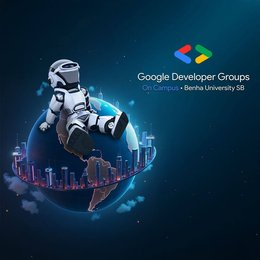
    </td>
    <td style="vertical-align:middle; border:none; background:transparent; padding-left:14px;">
      <p style="color:#1E1E1E; margin:0 0 2px 0; font-size:12px; letter-spacing:0.5px;"><span style="color:#4285F4;">&#9679;</span> <span style="color:#EA4335;">&#9679;</span> <span style="color:#FBBC04;">&#9679;</span> <span style="color:#34A853;">&#9679;</span>&nbsp; <b>Google Developer Groups on Campus &bull; Benha University SB</b></p>
      <h2 style="color:#1E1E1E; margin:4px 0 0 0; font-size:22px; font-weight:700;">GDGoC BUSB &mdash; <span style="color:#4285F4;">AI Track</span> Bootcamp</h2>
      <h3 style="color:#EA4335; margin:4px 0 0 0; font-size:16px; font-weight:600;">Session 4 Tasks: Data Preprocessing (Encoding, Scaling &amp; Feature Engineering)</h3>
      <p style="color:#1E1E1E; margin:6px 0 0 0; font-size:12px;"><b>Instructors:</b> Eng/Arwa Hamdy (Head AI) | Eng/Yassin Sanad (Vice Head) | Eng/Saif Alaswad (Vice Head)</p>
    </td>
  </tr>
</table>
<table style="width:100%; border-collapse:collapse; margin:0 0 15px 0;">
  <tr>
    <td style="height:8px; padding:0; border:none; background-color:#4285F4;"></td>
    <td style="height:8px; padding:0; border:none; background-color:#EA4335;"></td>
    <td style="height:8px; padding:0; border:none; background-color:#FBBC04;"></td>
    <td style="height:8px; padding:0; border:none; background-color:#34A853;"></td>
  </tr>
</table>

---

---

## **Setup: The Dataset**

> Today's topic is the **mobile phones market**. Download **`phones_data.csv`** (60 phones: brand, color, category, release date, RAM, storage, battery, camera, screen, weight, price, rating, units sold) and put it in the **same folder** as this notebook (in Google Colab: use the Files panel on the left and upload it).
>
> In all the tasks: work on a **copy** of the data and print what you did to check the result. Good luck!

## **Task 1: Load & First Look**

#### **Objective:**
*Learn how to use:*
- Reading a CSV file with Pandas
- `head()`, `shape` and `info()`
- `select_dtypes()`

  _df.select_dtypes(include=['object']) =>to select "object" cols_

 *Need help? Go back to the presentation: **Session 3 → Pandas (Data Reading, Data Exploration)***

---

#### **Task:**
> 1. Import `pandas` and read `phones_data.csv` into a DataFrame called `df`.
> 2. Show the first 3 rows and print the shape.
> 3. Display the `info()` of the data.
> 4. Print the list of the **text (object)** columns.
> 5. **Think:** Which of these text columns are *nominal* (no order) and which one is *ordinal* (has an order)? Why is `release_date` stored as text? *(Answer as a `# Q:` comment)*

---
#### **Example Output:**
```text
(head / info outputs)

Shape: (60, 13)
Object columns: ['brand', 'color', 'category', 'release_date']
```

In [ ]:
import pandas as pd
df = pd.read_csv("/content/phones_data - phones_data.csv")
df.head(3)

,brand,color,category,release_date,ram_gb,storage_gb,battery_mah,camera_mp,screen_inches,weight_g,price_usd,rating,units_sold_k
0,Apple,Gold,Mid-range,2022-10-24,8,256,4400,64,6.7,186,632,3.8,53
1,Realme,Silver,Budget,2021-10-04,4,64,4200,50,6.5,171,158,3.6,133
2,Oppo,Green,Flagship,2025-09-30,8,512,5200,50,6.9,214,876,4.3,47


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   brand          60 non-null     object 
 1   color          60 non-null     object 
 2   category       60 non-null     object 
 3   release_date   60 non-null     object 
 4   ram_gb         60 non-null     int64  
 5   storage_gb     60 non-null     int64  
 6   battery_mah    60 non-null     int64  
 7   camera_mp      60 non-null     int64  
 8   screen_inches  60 non-null     float64
 9   weight_g       60 non-null     int64  
 10  price_usd      60 non-null     int64  
 11  rating         60 non-null     float64
 12  units_sold_k   60 non-null     int64  
dtypes: float64(2), int64(7), object(4)
memory usage: 6.2+ KB


In [ ]:
obj = list(df.select_dtypes(include=['object']).columns)
sh = df.shape

print("Shape:",sh)
print("Object columns:",obj)

Shape: (60, 13)
Object columns: ['brand', 'color', 'category', 'release_date']


In [ ]:
#nominal : brand , color
#ordinal : category , release_date
#release_date stored as text as its the way pd read the date from the file and we can change it


## **Task 2: One-Hot Encoding**

#### **Objective:**
*Learn how to use:*
- `pd.get_dummies()` with `columns=` and `dtype=int`
- `columns` and `shape`

 *Need help? Go back to the presentation: **ENCODING → One-Hot Encoding***

---

#### **Task:**
> 1. Create `df_enc` as a copy of `df` and work on it from now on.
> 2. Apply **One-Hot Encoding** on the `brand` column (use `dtype=int` to get 0/1 instead of True/False).
> 3. Print the shape **before** and **after**, and the names of the new columns.
> 4. Show the first 3 rows of only the new brand columns.
> 5. **Think:** Why is One-Hot Encoding better than giving numbers 0-4 to the brands?

---
#### **Example Output:**
```text
Shape before: (60, 13) | after: (60, 17)
New columns: ['brand_Apple', 'brand_Oppo', 'brand_Realme', 'brand_Samsung', 'brand_Xiaomi']
   brand_Apple  brand_Oppo  brand_Realme  brand_Samsung  brand_Xiaomi
0            1           0             0              0             0
1            0           0             1              0             0
2            0           1             0              0             0
```

In [ ]:
df_enc = df.copy()
sh1 = df_enc.shape

brand2 = pd.get_dummies(df_enc[["brand"]] , dtype=int )
df_enc = pd.concat([df_enc , brand2] , axis=1)
df_enc.drop(columns="brand" , inplace=True)
sh2 = df_enc.shape

print("Shape before:" , sh1 , "| after" , sh2)
print("New columns:",list(brand2.columns))
print(brand2.head(3))
#One-hot Encoding is better here because giving numbers to the brands will make unreal order which misleads machine learning models

Shape before: (60, 13) | after (60, 17)
New columns: ['brand_Apple', 'brand_Oppo', 'brand_Realme', 'brand_Samsung', 'brand_Xiaomi']
   brand_Apple  brand_Oppo  brand_Realme  brand_Samsung  brand_Xiaomi
0            1           0             0              0             0
1            0           0             1              0             0
2            0           1             0              0             0


## **Task 3: Label Encoding**

#### **Objective:**
*Learn how to use:*
- `LabelEncoder()` from `sklearn.preprocessing`
- `fit_transform()` and `classes_`

 *Need help? Go back to the presentation: **ENCODING → Label Encoding***

---

#### **Task:**
> 1. Apply `LabelEncoder` on the `color` column and save the result in a new column `color_label` (keep the original).
> 2. Print the mapping between every color and its number (a dictionary).
> 3. Show 5 rows with `color` and `color_label` side by side.
> 4. **Think:** Is Label Encoding a good choice for `color`? What would a distance-based model think about Gold (2) and Green (3) vs Black (0)?

---
#### **Example Output:**
```text
{'Black': 0, 'Blue': 1, 'Gold': 2, 'Green': 3, 'Silver': 4}
    color  color_label
0    Gold            2
1  Silver            4
2   Green            3
3    Gold            2
4  Silver            4
```

In [ ]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
df_enc["color_label"] = label.fit_transform(df_enc["color"])

num = [int(n) for n in df_enc["color_label"].values]
color = list(df_enc["color"].values)
di = dict(zip(color , num))
di = dict(sorted(di.items() , key=lambda pair : pair[1]))
print(di)

s = df_enc[["color" , "color_label"]].head(5)
print(s)
#Label Encoding here is a bad idea as the model will think that "Green" is better than "Gold" and both are better than "Black" and its not True

{'Black': 0, 'Blue': 1, 'Gold': 2, 'Green': 3, 'Silver': 4}
    color  color_label
0    Gold            2
1  Silver            4
2   Green            3
3    Gold            2
4  Silver            4


## **Task 4: Ordinal Encoding**

#### **Objective:**
*Learn how to use:*
- `OrdinalEncoder(categories=[[...]])`
- `value_counts()` and `sort_index()`

 *Need help? Go back to the presentation: **ENCODING → Ordinal Encoding***

---

#### **Task:**
> 1. First, apply `LabelEncoder` on `category` into a temporary column `cat_wrong` and print the mapping. What is wrong with the order?
> 2. Now use `OrdinalEncoder` with the correct order: `Budget < Mid-range < Flagship`, and save it in `category_level`.
> 3. Print the `value_counts()` of `category_level` sorted by the index.
> 4. Drop the temporary column `cat_wrong`.
> 5. **Think:** Why does `LabelEncoder` give a wrong order here, and when do we choose Ordinal Encoding?

---
#### **Example Output:**
```text
{'Budget': 0, 'Flagship': 1, 'Mid-range': 2}
category_level
0    18
1    25
2    17
Name: count, dtype: int64
```

In [ ]:
df_enc["cat_wrong"] = label.fit_transform(df_enc["category"])
mapping = dict(zip(label.classes_, range(len(label.classes_)))) # since we needed the mapping again I searched for a shorter way instead of the long method
print(mapping) # The order is wrong because it sorted the words by letters  so Mid-range (2) came after Flagship (1) and its wrong

from sklearn.preprocessing import OrdinalEncoder
ordinal = OrdinalEncoder(categories=[["Budget", "Mid-range", "Flagship"]])
df_enc["category_level"] = ordinal.fit_transform(df_enc[["category"]]).astype(int)

print(df_enc["category_level"].value_counts().sort_index())

df_enc.drop(columns="cat_wrong", inplace=True)

{'Budget': 0, 'Flagship': 1, 'Mid-range': 2}
category_level
0    18
1    25
2    17
Name: count, dtype: int64


## **Task 5: Standardization**

#### **Objective:**
*Learn how to use:*
- `StandardScaler()` from `sklearn.preprocessing`
- `fit_transform()` with double brackets `[[ ]]`
- `mean()` and `std(ddof=0)`

 *Need help? Go back to the presentation: **SCALING → Standardization***

---

#### **Task:**
> 1. Apply `StandardScaler` on `price_usd` and save it in `price_std`.
> 2. Print the **mean** and the **std** of the new column, rounded to 2 decimals (use `std(ddof=0)` because `StandardScaler` uses the population std).
> 3. Print the original `price_usd` and `price_std` for the first 3 rows.
> 4. **Think:** What does a negative value in `price_std` mean?

---
#### **Example Output:**
```text
Mean: 0.0 | Std: 1.0
   price_usd  price_std
0        632       0.43
1        158      -1.49
2        876       1.42
```

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df_enc["price_std"] = scaler.fit_transform(df_enc[["price_usd"]])
m = df_enc["price_std"].mean()
s = df_enc["price_std"].std(ddof=0)
print(f"Mean: {m:.2F} | Std: {s:.2F}")
print(df_enc[["price_usd", "price_std"]].head(3).round(2))

Mean: 0.00 | Std: 1.00
   price_usd  price_std
0        632       0.43
1        158      -1.49
2        876       1.42


## **Task 6: Min-Max Scaling**

#### **Objective:**
*Learn how to use:*
- `MinMaxScaler()`
- Scaling **two columns at once**
- `min()`, `max()`, `median()`

 *Need help? Go back to the presentation: **SCALING → Min-Max Scaling***

---

#### **Task:**
> 1. Apply `MinMaxScaler` on `ram_gb` and `storage_gb` **together** and save them in `ram_mm` and `storage_mm`.
> 2. Print the min and max of both new columns.
> 3. Now apply `MinMaxScaler` on `units_sold_k` into `units_mm` and print its **median** (rounded to 2 decimals).
> 4. **Think:** Why is the median of `units_mm` so small? Which column is hurt by an outlier, and why is Min-Max *sensitive to outliers*?

---
#### **Example Output:**
```text
     ram_mm  storage_mm
min     0.0         0.0
max     1.0         1.0
Median of units_mm: 0.16
```

In [ ]:
from sklearn.preprocessing import MinMaxScaler
MinMax = MinMaxScaler()

df_enc[["ram_mm", "storage_mm"]] = MinMax.fit_transform(df_enc[["ram_gb", "storage_gb"]])

minmax_dict = {
    "ram_mm": [df_enc["ram_mm"].min() , df_enc["ram_mm"].max() ],
    "storage_mm": [df_enc["storage_mm"].min() , df_enc["storage_mm"].max() ]
}
df_minmax = pd.DataFrame(minmax_dict , index=["min" , "max"])

print(df_minmax)
df_enc["units_mm"] = MinMax.fit_transform(df_enc[["units_sold_k"]])
print(f"Median of units_mm: {df_enc['units_mm'].median():.2F}")
# MinMaxScaler is highly sensitive to outliers because it only uses the min and max values


     ram_mm  storage_mm
min     0.0         0.0
max     1.0         1.0
Median of units_mm: 0.16


## **Task 7: Scale the Right Way (No Leakage)**

#### **Objective:**
*Learn how to use:*
- `train_test_split` from `sklearn.model_selection`
- `fit()` on train only, then `transform()` on both

 *Need help? Go back to the presentation: **SCALING → the last question (When should the scaler be fitted?)***

---

#### **Task:**
> 1. Split `df_enc` into `train` (80%) and `test` (20%) with `random_state=42` (add `.copy()` to each).
> 2. Create a `StandardScaler` and **fit it on the train `price_usd` only**.
> 3. Transform both train and test into the new column `price_scaled`.
> 4. Print the mean of `price_scaled` for train and for test (2 decimals).
> 5. **Think:** Why must we NOT fit the scaler on the whole dataset before splitting? What would the test set "know" if we did?

---
#### **Example Output:**
```text
Train mean: 0.0 | Test mean: -0.38
```

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


train_df, test_df = train_test_split(df_enc, test_size=0.2, random_state=42)
train_df = train_df.copy()
test_df = test_df.copy()


scaler = StandardScaler()
scaler.fit(train_df[["price_usd"]])


train_df["price_scaled"] = scaler.transform(train_df[["price_usd"]])
test_df["price_scaled"] = scaler.transform(test_df[["price_usd"]])


train_mean = train_df["price_scaled"].mean()
test_mean = test_df["price_scaled"].mean()

print(f"Train mean: {train_mean:.2f} | Test mean: {test_mean:.2f}")


# To prevent Data Leakage

Train mean: 0.00 | Test mean: -0.38


## **Task 8: Mathematical Features**

#### **Objective:**
*Learn how to use:*
- Creating new columns from existing ones
- `round()`
- `groupby()` with `mean()`

 *Need help? Go back to the presentation: **FEATURE ENGINEERING → Mathematical Features (e.g. BMI)***

---

#### **Task:**
> 1. Create `price_per_gb` = `price_usd` / `storage_gb` (rounded to 2 decimals).
> 2. Create `price_per_ram` = `price_usd` / `ram_gb` (rounded to 2 decimals).
> 3. Print the average `price_per_gb` for each `category`.
> 4. **Think:** Why can `price_per_gb` be more meaningful than `price_usd` and `storage_gb` separately? *(Think about BMI from the slides)*

---
#### **Example Output:**
```text
category
Budget       2.77
Flagship     2.32
Mid-range    2.99
Name: price_per_gb, dtype: float64
```

In [ ]:
df_enc["price_per_gb"] = round(df_enc["price_usd"] / df_enc["storage_gb"] , 2)
df_enc["price_per_ram"] = round(df_enc["price_usd"]/df_enc["ram_gb"] , 2)
price_per_gb = df_enc.groupby("category")["price_per_gb"].mean().round(2)

print(price_per_gb)


category
Budget       2.77
Flagship     2.32
Mid-range    2.99
Name: price_per_gb, dtype: float64


## **Task 9: Date Features**

#### **Objective:**
*Learn how to use:*
- `pd.to_datetime()`
- The `.dt` accessor: `year`, `month`, `day_name()`
- Date arithmetic

 *Need help? Go back to the presentation: **FEATURE ENGINEERING → Date Features***

---

#### **Task:**
> 1. Convert `release_date` to the `datetime` type and print its `dtype`.
> 2. Create the columns `release_year`, `release_month` and `release_day` (the name of the day, e.g. Monday).
> 3. Create `phone_age` = `2026 - release_year`.
> 4. Print how many phones were released in each year (sorted by year).
> 5. **Think:** Why can't a model use the text "2022-10-24" directly, and what extra information can we get from the month?

---
#### **Example Output:**
```text
dtype: datetime64[us]
release_year
2021    16
2022    13
2023    11
2024     9
2025    11
Name: count, dtype: int64
```

In [ ]:
df_enc["release_date"] = pd.to_datetime(df_enc["release_date"])
print("dtype:", df_enc["release_date"].dtype)
df_enc["release_year"] = df_enc["release_date"].dt.year
df_enc["release_month"] = df_enc["release_date"].dt.month
df_enc["release_day"] = df_enc["release_date"].dt.day_name()

df_enc["phone_age"] =2026 - df_enc["release_year"]

print(df_enc["release_year"].value_counts().sort_index())

# Models cannot do math on raw text strings

dtype: datetime64[ns]
release_year
2021    16
2022    13
2023    11
2024     9
2025    11
Name: count, dtype: int64


# 🚀 **BONUS SECTION: THE HACKER'S DEN** 🧠
---
> **"Easy is boring."**  
> *This section is for those who want to push their limits. These tasks combine multiple concepts and need real problem-solving. No training wheels here, show us what you can do!* 🔥

## **Bonus 1: Robust Scaling**

#### **Objective:**
*Learn how to use:*
- Searching for something new (**RobustScaler**)
- Comparing 3 scalers on the same column
- `agg()`

 *Need help? Go back to the presentation: **SCALING → Search for: What is Robust Scaling?***

---

#### **Task:**
> 1. Search for what `RobustScaler` does and import it from `sklearn.preprocessing`.
> 2. Scale `units_sold_k` with `StandardScaler`, `MinMaxScaler` and `RobustScaler` into 3 separate new columns.
> 3. Print the `min`, `max` and `median` of the 3 new columns (2 decimals) in one table.
> 4. **Think:** Which scaler handles the viral phone (420k) best, and why? *(No hints this time!)*

---
#### **Example Output:**
```text
        units_std  units_minmax  units_robust
min         -1.32          0.00         -1.42
max          5.97          1.00          7.40
median      -0.14          0.16          0.00
```

## **Bonus 2: Domain-Driven Features**

#### **Objective:**
*Learn how to use:*
- Creating features that carry **useful information**
- `nlargest()` and `groupby()` with `mean()`

 *Need help? Go back to the presentation: **FEATURE ENGINEERING → Important Point (not as many features as possible!)***

---

#### **Task:**
> 1. Create `value_score` = `rating` / `price_usd` * 100 (2 decimals): how much rating you get per dollar.
> 2. Create `battery_per_gram` = `battery_mah` / `weight_g` (2 decimals).
> 3. Print the top 5 phones by `value_score` (show `category`, `price_usd`, `rating`, `value_score`).
> 4. Print the average `value_score` for each `category`.
> 5. **Think:** Which of the two new features is more meaningful for a phone buyer? Why is it a bad idea to create as many features as possible?

---
#### **Example Output:**
```text
   category  price_usd  rating  value_score
1    Budget        158     3.6         2.28
51   Budget        169     3.6         2.13
45   Budget        169     3.2         1.89
6    Budget        188     3.4         1.81
8    Budget        190     3.3         1.74
category
Budget       1.67
Flagship     0.51
Mid-range    0.75
Name: value_score, dtype: float64
```

## **Bonus 3: The Preprocessing Pipeline**

#### **Objective:**
*Learn how to use:*
- Writing a **reusable function** that wraps a full workflow
- Everything from Tasks 1 to 9 in one place
- `select_dtypes()`, `isnull()`, `to_csv()`

---

#### **Task:**
> 1. Build a function `preprocess_phones(path)` that reads the raw CSV and returns a fully processed DataFrame.
> 2. Requirements: One-Hot `brand`, Ordinal `category` (in the right order), Label Encode `color`, date features (`release_year`, `release_month`, `phone_age`), `price_per_gb`, and `StandardScaler` on `ram_gb`, `storage_gb`, `battery_mah`, `camera_mp`, `screen_inches`, `weight_g` (replace the original values).
> 3. Drop the columns that are no longer needed (`release_date`, `color`, `category`).
> 4. Call it on `phones_data.csv` and print: the original shape, the new shape, the number of nulls, and the list of remaining object columns (should be empty).
> 5. Save the result to `phones_processed.csv` (without the index).
> 6. **Think:** In this function we fit the scaler on the *whole* data. Why is this a problem when we want to train a model, and how would you fix it?

---
#### **Example Output:**
```text
Original shape: (60, 13) | New shape: (60, 20)
Nulls: 0
Object columns: []
Saved to phones_processed.csv
```

---
<div style="background-color:#F0F0F0; border:2px solid #1E1E1E; border-radius:16px; padding:14px; text-align:center; font-family:'Google Sans',Roboto,Arial,sans-serif; color:#1E1E1E;">
<b style="font-size:16px;">🎉 Good luck!</b><br>Solve it, test it, break it, fix it &mdash; that is how engineers grow.<br>
<span style="font-size:12px;">GDGoC BUSB &bull; Google Developer Groups on Campus &bull; Benha University SB</span>
</div>
